In [1]:
import pandas as pd
import matplotlib.pyplot as plt

views = pd.read_csv("../data/kepler_test_run.csv", header=None)
meta = pd.read_csv("../data/kepler_test_run_meta.csv")
print(views.shape)
print(meta["original_label"].value_counts())

(49, 202)
original_label
AFP    27
NTP    13
PC      9
Name: count, dtype: int64


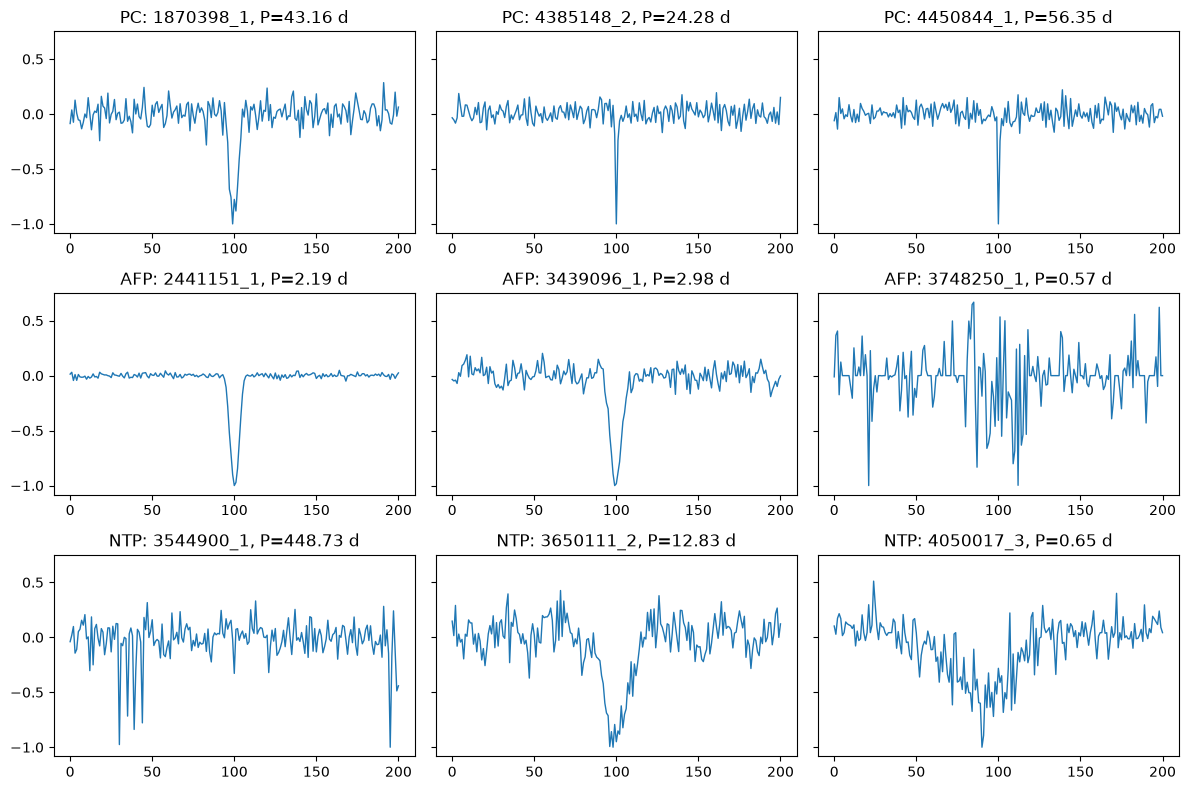

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharey=True)
for row, cls in enumerate(["PC", "AFP", "NTP"]):
    idx = meta.index[meta["original_label"] == cls][:3]
    for col, i in enumerate(idx):
        axes[row, col].plot(views.iloc[i, :201].values, lw=1)
        axes[row, col].set_title(
            f"{cls}: {meta.loc[i, 'signal_id']}, P={meta.loc[i, 'period_days']:.2f} d")
plt.tight_layout()
plt.show()

In [3]:
# how many bins exactly equal 0 and what fraction of the period is masked
meta["dur_frac"] = meta["duration_days"] / meta["period_days"]
meta["zero_bins"] = (views.iloc[:, :201] == 0).sum(axis=1)
print(meta[["signal_id", "original_label", "period_days", "duration_days", "dur_frac", "zero_bins"]]
      .sort_values("zero_bins", ascending=False).head(10))

     signal_id original_label  period_days  duration_days  dur_frac  zero_bins
41   9773512_3            AFP     0.568307       0.067542  0.118847        100
5    3748250_1            AFP     0.565168       0.051833  0.091713         76
18   6451605_2            AFP     0.556286       0.139208  0.250246         49
10   4947130_3            AFP     0.711900       0.099500  0.139767         42
15   6230921_1            NTP     0.539169       0.167125  0.309968         23
34   8690471_1            NTP     1.059110       0.145250  0.137143         21
14   5642620_2            AFP     0.986791       0.042833  0.043407         12
22   7097965_1             PC     7.720860       0.065792  0.008521          3
9    4450844_1             PC    56.348100       0.361208  0.006410          2
42  10154592_1            NTP   538.360000       0.609167  0.001132          2


In [4]:
import numpy as np
for s in ["train", "test"]:
    v = np.genfromtxt(f"../data/kepler_dr24_{s}.csv", delimiter=",")[:, :-1]
    m = np.abs(v).max(axis=1)          # найбільше значення в кожному виді
    print(f"{s}: median={np.median(m):.1f}  p99={np.percentile(m, 99):.1f}  max={m.max():.1f}  "
          f">10: {(m > 10).sum()}  >100: {(m > 100).sum()}")

train: median=1.0  p99=2.7  max=6959.3  >10: 1  >100: 1
test: median=1.0  p99=1.9  max=2.5  >10: 0  >100: 0
